# ДЗ 2. Параллелизм

Исследуем, какие изменения исполнения позволяют обрабатывать больше **полезных токенов в секунду** при неизменной модели. По сути, хотим посмотреть что за оптимизации бывают на одном GPU (в нашем случае к сожалению 1 A100😭), какой прирост по утилизации GPU и скорости модели сможем выбить.

## Сетап и смысл сравнения

Модель Qwen3 создаётся со случайными весами: 12 слоёв, hidden size 2048, intermediate size 8192, 16 attention heads и 8 KV heads. Токенизатор — `ai-forever/rugpt3small_based_on_gpt2`. Данные — русская Wikipedia `20231101.ru`.

Неизменны `max_length=512`, BF16, TF32, fused AdamW, `learning_rate=3e-4`, `weight_decay=0.01`, `constant_with_warmup` с 200 шагами разогрева, оба seed=42 и код метрик. Микробатч baseline равен 32, accumulation — 2; SDPA уже включён, остальные исследуемые оптимизации выключены.

Все опыты выполняем последовательно на одной и той же A100, не меняя окружение.


In [1]:
import json
import os
import re
import shutil
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 55)


In [2]:
ROOT = Path.cwd().resolve()
PYTHON = ROOT / '.venv' / 'bin' / 'python'
SCRIPTS = ROOT / 'scripts'
RESULTS = ROOT / 'results'
for folder in [SCRIPTS, RESULTS]:
    folder.mkdir(exist_ok=True)


## План опытов

| Имя | Изменение относительно baseline | Время, с | Основное сравнение |
|---|---|---:|---|
| `baseline` | SDPA, batch 32, accumulation 2 | 300 | исходная точка |
| `batch16` | batch 16, accumulation 4 | 90 | цена маленького микробатча |
| `batch64` | batch 64, accumulation 1 | 90 | загрузка GPU и предел памяти |
| `checkpoint` | activation checkpointing | 90 | экономия памяти и пересчёт |
| `checkpoint64` | checkpointing + batch 64 / accumulation 1 | 90 | окупается ли пересчёт большим батчем |
| `fa2` | FlashAttention 2 | 90 | backend attention при обычном padding |
| `fa2_padding_free` | FA2 + padding-free | 90 | устранение padding без packing |
| `fa2_packing` | FA2 + padding-free + BFD packing | 90 | дополнительный эффект упаковки |
| `compile` | torch.compile с SDPA | 90 | исполнение графа и стоимость компиляции |
| `liger` | Liger с SDPA | 90 | fused kernels |
| `offload` | activation offloading с SDPA | 90 | обмен GPU-памяти на передачи CPU–GPU |
| `fa2_packing_liger` | FA2 + padding-free + packing + Liger | 90 | совместный эффект упаковки и kernels |


In [3]:
from train import TRAINING_CONFIG as base_config

template = (ROOT / 'train.py').read_text(encoding='utf-8')
config_columns = {
    'per_device_train_batch_size': 'batch',
    'gradient_accumulation_steps': 'accum',
    'gradient_checkpointing': 'ckpt',
    'packing': 'pack',
    'padding_free': 'pad_free',
    'torch_compile': 'compile',
    'use_liger_kernel': 'liger',
    'activation_offloading': 'offload',
}
metric_columns = [
    'train_seconds', 'tokens_per_second', 'tokens_per_second_including_warmup',
    'peak_allocated_gib', 'peak_reserved_gib', 'validation_loss',
    'optimizer_steps', 'target_tokens', 'measured_steps', 'measured_seconds',
]


In [4]:
def run(name, seconds=90, attention='sdpa', **changes):
    output = RESULTS / name
    assert not output.exists(), f'{name} уже существует; выберите новое имя'
    config = base_config | changes | {'output_dir': f'results/{name}'}

    source = template.replace('TRAIN_SECONDS: float = 300', f'TRAIN_SECONDS: float = {seconds}')
    if attention != 'sdpa':
        source = source.replace('ATTENTION_IMPLEMENTATION: str = "sdpa"',
                                f'ATTENTION_IMPLEMENTATION: str = {attention!r}')
    for key, value in config.items():
        if value != base_config[key]:
            source = re.sub(rf'^    {key}=.*,$', f'    {key}={value!r},', source, flags=re.M)
    script = SCRIPTS / f'{name}.py'
    script.write_text(source, encoding='utf-8')

    run_env = dict(os.environ,
                   CUDA_VISIBLE_DEVICES=os.environ.get('CUDA_VISIBLE_DEVICES', '0').split(',')[0],
                   TORCHINDUCTOR_CACHE_DIR=str(ROOT / 'compile_cache' / name),
                   TRITON_CACHE_DIR=str(ROOT / 'triton_cache' / name))
    started = time.perf_counter()
    process = subprocess.run([str(PYTHON), '-u', str(script)], cwd=ROOT, env=run_env,
                             capture_output=True, text=True)
    record = dict(name=name, TRAIN_SECONDS=seconds, ATTENTION_IMPLEMENTATION=attention,
                  TRAINING_CONFIG=config, returncode=process.returncode,
                  wall_seconds=time.perf_counter() - started)
    output.mkdir(exist_ok=True)
    shutil.copyfile(script, output / 'train.py')
    (output / 'config.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
    if process.returncode != 0:
        print(process.stderr or process.stdout)
        return
    summary = json.loads((output / 'summary.json').read_text())
    display(pd.DataFrame([summary], index=[name])[metric_columns].round(3))


## Baseline: исходный скрипт, 300 секунд

In [5]:
run('baseline', seconds=300)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
baseline,300.313,6973.238,6937.966,41.235,43.439,6.599,366,2083560,356,290.55


### Сколько работы тратится на padding
Тут нам интересно посмотреть, а сколько у нас паддинг берет на себя. Так можем примерно прикинуть, насколько padding-free даст нам выигрыш.

In [6]:
from datasets import load_from_disk

dataset = load_from_disk(str(ROOT / 'data' / 'dataset'))
sample = dataset['train'].shuffle(seed=42).select(range(min(4096, len(dataset['train']))))
lengths = np.array([len(ids) for ids in sample['input_ids']])
display(pd.Series(lengths, name='Токенов с EOS').describe(percentiles=[0.5, 0.9, 0.95]).round(1))

padding_rows = []
for batch in [16, 32, 64]:
    batches = lengths[:len(lengths) // batch * batch].reshape(-1, batch)
    padded_tokens = batch * batches.max(axis=1).sum()
    padding_rows.append({'microbatch': batch, 'padding_%': 100 * (1 - batches.sum() / padded_tokens)})
display(pd.DataFrame(padding_rows).round(2))


count    4096.0
mean       90.8
std        61.0
min        33.0
50%        72.0
90%       168.0
95%       211.2
max       512.0
Name: Токенов с EOS, dtype: float64

,microbatch,padding_%
0,16,62.36
1,32,67.75
2,64,72.25


## Микробатч и gradient accumulation

Сравниваем `16×4`, `32×2` и `64×1`. Гипотеза: больший микробатч лучше загружает GPU и сокращает число проходов на шаг оптимизатора, но требует больше памяти и может увеличить padding. Смотрим на полезные токены/с, а не только на число шагов.

In [8]:
run('batch16', per_device_train_batch_size=16, gradient_accumulation_steps=4)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
batch16,90.587,7980.782,7848.324,24.212,25.996,8.05,125,710956,115,81.881


In [9]:
run('batch64', per_device_train_batch_size=64, gradient_accumulation_steps=1)

`torch_dtype` is deprecated! Use `dtype` instead!
Traceback (most recent call last):
  File "/home/saumnov/study/HSE_LLM/2/scripts/batch64.py", line 303, in <module>
    main()
  File "/home/saumnov/study/HSE_LLM/2/scripts/batch64.py", line 293, in main
    trainer.train()
  File "/home/saumnov/study/HSE_LLM/2/.venv/lib/python3.11/site-packages/transformers/trainer.py", line 2325, in train
    return inner_training_loop(
           ^^^^^^^^^^^^^^^^^^^^
  File "/home/saumnov/study/HSE_LLM/2/.venv/lib/python3.11/site-packages/transformers/trainer.py", line 2674, in _inner_training_loop
    tr_loss_step = self.training_step(model, inputs, num_items_in_batch)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/saumnov/study/HSE_LLM/2/scripts/batch64.py", line 155, in training_step
    return super().training_step(model, inputs, num_items_in_batch)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/saumnov/study/HSE_LLM/2/.ve

Видим, что batch 64 дает OOM. Тут как раз следующий эксперимент покажет, можно ли с помощью checkpointing сделать такой батч доступным.

## Checkpointing: цена экономии памяти

Сначала включаем checkpointing при исходном `32×2`, затем сочетаем его с `64×1`. Ожидаемый компромисс — меньше сохранённых активаций, но дополнительные вычисления при backward.

In [10]:
run('checkpoint', gradient_checkpointing=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
checkpoint,90.614,5971.862,5833.984,17.391,23.971,8.236,93,528642,83,78.896


In [11]:
run('checkpoint64', gradient_checkpointing=True,
    per_device_train_batch_size=64, gradient_accumulation_steps=1)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
checkpoint64,90.057,5225.903,5103.938,25.807,27.432,8.303,81,459644,71,76.955


## Attention, padding-free и packing

Сначала заменяем только SDPA на FlashAttention 2. SDPA уже умеет выбирать fused attention kernels, поэтому большой выигрыш от одной замены заранее не гарантирован.

Затем включаем padding-free без packing и лишь после этого добавляем BFD packing. В TRL стратегия `bfd` сама активирует padding-free; здесь флаг указан явно. Используем FA2, чтобы обработка объединённого батча учитывала границы примеров. При padding-free физический тензор может быть длиннее 512, но отдельные последовательности и блоки packing по-прежнему ограничены 512; границы задаются position IDs.

In [12]:
run('fa2', attention='flash_attention_2')

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
fa2,90.654,7688.88,7531.762,39.294,41.006,8.099,120,682785,110,81.325


In [13]:
run('fa2_padding_free', attention='flash_attention_2', padding_free=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
fa2_padding_free,90.258,19294.91,19192.578,15.106,21.24,6.872,305,1732278,295,86.8


In [14]:
run('fa2_packing', attention='flash_attention_2', padding_free=True, packing=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
fa2_packing,91.351,22260.254,22067.24,40.15,76.201,8.216,63,2015858,53,76.202


## Компиляция и fused kernels

`torch.compile` проверяем отдельно на baseline: возможный выигрыш от исполнения графа конкурирует со стоимостью компиляции и перекомпиляций при разных длинах батчей.

Liger сначала включаем отдельно с SDPA. Гипотеза — fused kernels снизят затраты на промежуточные тензоры; проверяем и скорость, и память.

In [ ]:
run('compile', torch_compile=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
compile,101.7,None,63.314,25.808,26.107,11.235,1,6439,0,0


Мы получили, что модель слишком долго компилировалась, тем самым за 100 секунд мы не получили достаточно шагов, что бы составить метрики. Запустим этот же эксперимент с большим временем.

In [22]:
run('compile_500s', torch_compile=True, seconds=500)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
compile_500s,500.228,10845.4,8631.444,31.169,38.242,5.455,755,4317692,745,392.812


In [16]:
run('liger', use_liger_kernel=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
liger,90.671,7174.776,6646.761,26.832,28.467,8.158,106,602667,96,75.986


## Activation offloading

Перенос активаций в CPU RAM может снизить пик GPU-памяти ценой передач между CPU и GPU. В этом опыте сохраняем `32×2`, чтобы увидеть сам обмен памяти на время, без изменения батча. Если исходный режим уже помещается, ожидаем прежде всего экономию памяти; влияние на скорость установит замер.

In [17]:
run('offload', activation_offloading=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
offload,90.307,2199.996,1908.356,28.517,32.619,10.452,31,172337,21,52.206


## Сочетание packing и Liger

Добавляем Liger к уже измеренной конфигурации `fa2_packing`, сохраняя `32×2`. Проверяем, дополняют ли fused kernels устранение padding. Выигрыши могут не перемножаться: после устранения одной группы затрат ограничением становится другая.

In [18]:
run('fa2_packing_liger', attention='flash_attention_2',
    padding_free=True, packing=True, use_liger_kernel=True)

,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
fa2_packing_liger,90.344,26166.278,24793.766,25.821,33.148,8.173,70,2239972,60,73.392


## Сводные результаты

In [23]:
def collect_results():
    rows = []
    for path in sorted(RESULTS.glob('*/config.json')):
        record = json.loads(path.read_text())
        summary_path = path.with_name('summary.json')
        summary = json.loads(summary_path.read_text()) if summary_path.exists() else {}
        status = 'failed'
        if record['returncode'] == 0 and summary:
            status = 'ok' if summary.get('tokens_per_second') is not None else 'no_measurement'
        row = dict(experiment=record['name'], status=status, budget_s=record['TRAIN_SECONDS'],
                   attention=record['ATTENTION_IMPLEMENTATION'], wall_s=record['wall_seconds'])
        row.update({short: record['TRAINING_CONFIG'][key] for key, short in config_columns.items()})
        rows.append(row | summary)
    return pd.DataFrame(rows)

results = collect_results()
display(results.round(3))
results.to_csv(ROOT / 'experiments.csv', index=False)


,experiment,status,budget_s,attention,wall_s,batch,accum,ckpt,pack,pad_free,compile,liger,offload,train_seconds,optimizer_steps,target_tokens,tokens_per_second_including_warmup,warmup_steps,measured_steps,measured_seconds,tokens_per_second,seconds_per_optimizer_step,peak_allocated_gib,peak_reserved_gib,validation_loss,validation_target_tokens
0,baseline,ok,300,sdpa,340.641,32,2,False,False,False,False,False,False,300.313,366.0,2083560.0,6937.966,10.0,356.0,290.550,6973.238,0.816,41.235,43.439,6.599,50694.0
1,batch16,ok,90,sdpa,130.681,16,4,False,False,False,False,False,False,90.587,125.0,710956.0,7848.324,10.0,115.0,81.881,7980.782,0.712,24.212,25.996,8.050,50694.0
2,batch64,failed,90,sdpa,50.782,64,1,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,checkpoint,ok,90,sdpa,131.067,32,2,True,False,False,False,False,False,90.614,93.0,528642.0,5833.984,10.0,83.0,78.896,5971.862,0.951,17.391,23.971,8.236,50694.0
4,checkpoint64,ok,90,sdpa,130.758,64,1,True,False,False,False,False,False,90.057,81.0,459644.0,5103.938,10.0,71.0,76.955,5225.903,1.084,25.807,27.432,8.303,50694.0
5,compile,no_measurement,90,sdpa,146.055,32,2,False,False,False,True,False,False,101.700,1.0,6439.0,63.314,10.0,0.0,0.000,NaN,NaN,25.808,26.107,11.235,50694.0
6,compile_500s,ok,500,sdpa,544.700,32,2,False,False,False,True,False,False,500.228,755.0,4317692.0,8631.444,10.0,745.0,392.812,10845.400,0.527,31.169,38.242,5.455,50694.0
7,fa2,ok,90,flash_attention_2,131.150,32,2,False,False,False,False,False,False,90.654,120.0,682785.0,7531.762,10.0,110.0,81.325,7688.880,0.739,39.294,41.006,8.099,50694.0
8,fa2_packing,ok,90,flash_attention_2,135.310,32,2,False,True,True,False,False,False,91.351,63.0,2015858.0,22067.240,10.0,53.0,76.202,22260.254,1.438,40.150,76.201,8.216,50694.0
9,fa2_packing_liger,ok,90,flash_attention_2,131.617,32,2,False,True,True,False,True,False,90.344,70.0,2239972.0,24793.766,10.0,60.0,73.392,26166.278,1.223,25.821,33.148,8.173,50694.0


In [24]:
finite = np.isfinite(results[['tokens_per_second', 'validation_loss']]).all(axis=1)
valid = results[finite & (results['status'] == 'ok') & (results['tokens_per_second'] > 0)].copy()
baseline = valid.set_index('experiment').loc['baseline']
valid['relative_tps'] = valid['tokens_per_second'] / baseline['tokens_per_second']
valid['tokens_per_step'] = valid['target_tokens'] / valid['optimizer_steps']
display(valid[['experiment', 'budget_s', 'relative_tps', 'tokens_per_second',
               'peak_allocated_gib', 'validation_loss', 'optimizer_steps',
               'tokens_per_step', 'measured_steps']].sort_values('tokens_per_second', ascending=False).round(3))


,experiment,budget_s,relative_tps,tokens_per_second,peak_allocated_gib,validation_loss,optimizer_steps,tokens_per_step,measured_steps
9,fa2_packing_liger,90,3.752,26166.278,25.821,8.173,70.0,31999.600,60.0
8,fa2_packing,90,3.192,22260.254,40.150,8.216,63.0,31997.746,53.0
10,fa2_padding_free,90,2.767,19294.910,15.106,6.872,305.0,5679.600,295.0
6,compile_500s,500,1.555,10845.400,31.169,5.455,755.0,5718.797,745.0
1,batch16,90,1.144,7980.782,24.212,8.050,125.0,5687.648,115.0
7,fa2,90,1.103,7688.880,39.294,8.099,120.0,5689.875,110.0
11,liger,90,1.029,7174.776,26.832,8.158,106.0,5685.538,96.0
0,baseline,300,1.000,6973.238,41.235,6.599,366.0,5692.787,356.0
3,checkpoint,90,0.856,5971.862,17.391,8.236,93.0,5684.323,83.0
4,checkpoint64,90,0.749,5225.903,25.807,8.303,81.0,5674.617,71.0


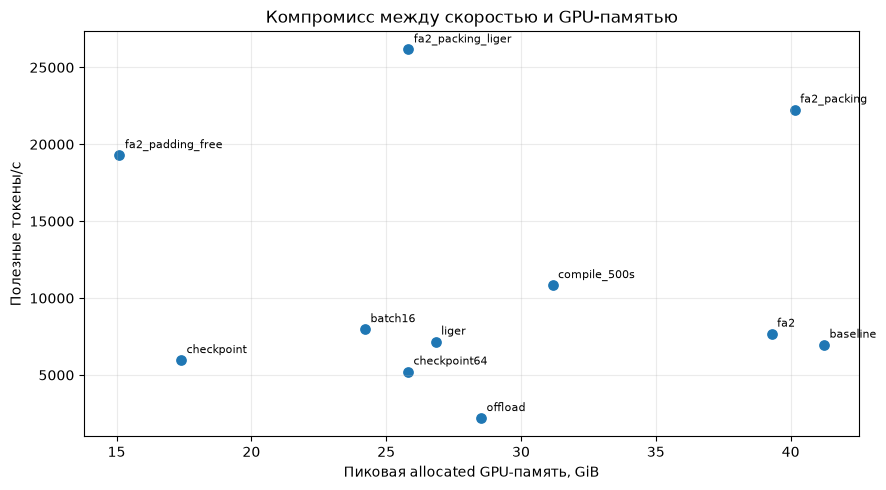

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(valid['peak_allocated_gib'], valid['tokens_per_second'], s=45)
for row in valid.itertuples():
    ax.annotate(row.experiment, (row.peak_allocated_gib, row.tokens_per_second),
                xytext=(4, 5), textcoords='offset points', fontsize=8)
ax.set(xlabel='Пиковая allocated GPU-память, GiB', ylabel='Полезные токены/с',
       title='Компромисс между скоростью и GPU-памятью')
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [26]:
pairs = [
    ('baseline', 'batch64'),
    ('baseline', 'checkpoint'),
    ('checkpoint', 'checkpoint64'),
    ('baseline', 'fa2'),
    ('fa2', 'fa2_padding_free'),
    ('fa2_padding_free', 'fa2_packing'),
    ('baseline', 'liger'),
    ('fa2_packing', 'fa2_packing_liger'),
    ('baseline', 'offload'),
]
by_name = valid.set_index('experiment')
effects = []
for reference, candidate in pairs:
    if reference in by_name.index and candidate in by_name.index:
        before, after = by_name.loc[reference], by_name.loc[candidate]
        effects.append({'сравнение': f'{candidate} / {reference}',
                        'скорость, ×': after.tokens_per_second / before.tokens_per_second,
                        'изменение памяти, GiB': after.peak_allocated_gib - before.peak_allocated_gib})
display(pd.DataFrame(effects).round(3))


,сравнение,"скорость, ×","изменение памяти, GiB"
0,checkpoint / baseline,0.856,-23.844
1,checkpoint64 / checkpoint,0.875,8.415
2,fa2 / baseline,1.103,-1.941
3,fa2_padding_free / fa2,2.509,-24.189
4,fa2_packing / fa2_padding_free,1.154,25.045
5,liger / baseline,1.029,-14.403
6,fa2_packing_liger / fa2_packing,1.175,-14.330
7,offload / baseline,0.315,-12.718


## Что получилось

Бейзлайн дал **6 973 токена/с** при **41,2 GiB** памяти. Основные выводы:

- **Меньший батч помог:** `16×4` дал 7 981 токен/с (+14%) и снизил память до 24,2 GiB. Батч 64 без checkpointing не поместился.
- **Checkpointing сэкономил память, но замедлил обучение:** 17,4 GiB и 5 972 токена/с. С ним батч 64 поместился, но стал ещё медленнее. Offloading тоже не помог скорости: всего 2 200 токенов/с.
- **Самый большой прирост дал padding-free:** вместе с FA2 получилось 19 295 токенов/с — в 2,5 раза больше, чем с одним FA2. Это согласуется с большим количеством padding в исходных батчах: около 68% позиций.
- **Packing + Liger оказались лучшим сочетанием:** 26 166 токенов/с при 25,8 GiB. Liger добавил к packing ещё 17,5% скорости, хотя отдельно дал лишь около 3%.
- **Для compile 90 секунд оказалось мало:** выполнился только один шаг, поэтому основная метрика не посчиталась. За 500 секунд получилось 10 845 токенов/с. Долгий старт согласуется с затратами на компиляцию, но отдельно её время мы не измеряли.

По loss среди коротких запусков лучше `fa2_padding_free`: **6,87** против **8,17** у `fa2_packing_liger`. У них 305 и 70 шагов соответственно: packing ещё не прошёл разогрев learning rate в 200 шагов. Поэтому высокий throughput пока не означает лучший loss.

На 300 секунд выбираем **`fa2_packing_liger`** по главной метрике задания. Пока он быстрее бейзлайна примерно в **3,75 раза**; итоговое ускорение и loss сравним после запуска с одинаковым бюджетом.


In [28]:
run('final_300', seconds=300, attention='flash_attention_2',
    padding_free=True, packing=True, use_liger_kernel=True)


,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
final_300,300.329,26265.265,25872.39,25.836,33.148,6.208,243,7770222,233,283.669


Сравниваем `final_300` с бейзлайном: оба обучаются с нуля по 300 секунд на одной GPU. Ускорение **S** — отношение их `tokens_per_second`. Смотрим также на память и loss: у packing было меньше шагов за то же время, поэтому одного выигрыша в скорости недостаточно для вывода о качестве.


In [29]:
comparison = pd.DataFrame({name: json.loads((RESULTS / name / 'summary.json').read_text())
                           for name in ['baseline', 'final_300']}).T
display(comparison[metric_columns].round(3))
S = comparison.loc['final_300', 'tokens_per_second'] / comparison.loc['baseline', 'tokens_per_second']
loss_delta = comparison.loc['final_300', 'validation_loss'] - comparison.loc['baseline', 'validation_loss']
print(f'Ускорение S = {S:.3f}×; изменение validation loss = {loss_delta:+.4f}')


,train_seconds,tokens_per_second,tokens_per_second_including_warmup,peak_allocated_gib,peak_reserved_gib,validation_loss,optimizer_steps,target_tokens,measured_steps,measured_seconds
baseline,300.313,6973.238,6937.966,41.235,43.439,6.599,366.0,2083560.0,356.0,290.550
final_300,300.329,26265.265,25872.390,25.836,33.148,6.208,243.0,7770222.0,233.0,283.669


Ускорение S = 3.767×; изменение validation loss = -0.3905


В итоге оставляем **FA2 + padding-free + BFD packing + Liger**, batch 32, accumulation 2. За одинаковые 300 секунд:

- Скорость выросла с **6 973 до 26 265 токенов/с**, итоговое ускорение **S = 3,767×**.
- Пиковая GPU-память (allocated) снизилась с **41,24 до 25,84 GiB**, примерно на **37%**.
- Validation loss улучшился с **6,599 до 6,208** (на 0,391).

Финальный запуск обработал **7,77 млн полезных токенов** против 2,08 млн у бейзлайна, хотя шагов было меньше: 243 против 366. С packing на один шаг приходится больше токенов. Теперь пройден и разогрев learning rate в 200 шагов: отставание по loss из короткого опыта в финальном сравнении не сохранилось. При одинаковом бюджете выбранная конфигурация дала и ускорение, и меньший loss.

Ну и в финале сохраним итоговые `train_final.py`, `summary.json` и таблицу экспериментов.


In [30]:
shutil.copyfile(RESULTS / 'final_300' / 'train.py', ROOT / 'train_final.py')
shutil.copyfile(RESULTS / 'final_300' / 'summary.json', ROOT / 'summary.json')
collect_results().to_csv(ROOT / 'experiments.csv', index=False)
print('Сохранены train_final.py, summary.json и experiments.csv')


Сохранены train_final.py, summary.json и experiments.csv
